# ДЗ3. Метрики, порог и калибровка

Предсказываю, опоздает ли заказ. Таргет `is_late`:
1 — заказ опоздал, 0 — доставлен вовремя

Сравниваю две модели HistGradientBoostingClassifier:
- модель A — с обычными весами классов;
- модель B — с `class_weight="balanced"`

Данные разделены на train, validation и test в пропорции 60/20/20.
На validation выбираю порог и обучаю калибровку,
на test показываю итоговые метрики.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    average_precision_score,
    precision_recall_curve,
    brier_score_loss,
    log_loss,
)

SEED = 42

data = pd.read_csv("data/olist_delivery_clean.csv")

print("Размер данных:", data.shape)
display(data.head())
display(data["is_late"].value_counts())

Размер данных: (96470, 22)


,order_purchase_timestamp,customer_unique_id,seller_id,customer_state,seller_state,same_state,distance_km,estimated_delivery_days,shipping_limit_days,n_items,...,total_price,total_freight,freight_share,product_category,product_weight_g,product_volume_cm3,payment_type,payment_installments,payment_value,is_late
0,2016-09-15 12:16:38,830d5b7aaa3b6f1e9ad63703bec97d23,ecccfa2bb93b34a3bf033cc5d1dcdc69,SP,PR,0,566.040211,18.488449,4.454803,3,...,134.97,8.49,0.059180,beleza_saude,1000.0,4096.0,NaN,NaN,NaN,1
1,2016-10-03 09:44:50,32ea3bdedab835c3aa6cb68ce66565ef,522620dcb18a6b31cd7bdf73665113a9,SP,PR,0,708.535291,23.593866,18.279514,1,...,29.90,15.56,0.342279,relogios_presentes,300.0,4096.0,boleto,1.0,45.46,0
2,2016-10-03 16:56:50,2f64e403852e6893ae37485d5fcacdaf,f09b760d23495ac9a7e00d29b769007c,RS,SP,0,915.734331,34.293866,17.983981,1,...,21.90,17.19,0.439754,esporte_lazer,400.0,4096.0,boleto,1.0,39.09,0
3,2016-10-03 21:13:36,61db744d2f835035a5625b59350c6b63,45d33f715e24d15a6ccf5c17b3a23e3c,RS,SP,0,818.048765,56.115556,17.795023,1,...,36.49,17.24,0.320864,esporte_lazer,767.0,4160.0,boleto,1.0,53.73,0
4,2016-10-03 22:06:03,8d3a54507421dbd2ce0a1d58046826e0,cca3071e3e9bb7d12640c9fbe2301306,SP,SP,1,212.149919,50.079132,17.761840,1,...,119.90,13.56,0.101603,moveis_decoracao,2050.0,14960.0,credit_card,6.0,133.46,0


is_late
0    88644
1     7826
Name: count, dtype: int64

In [2]:
excluded_columns = [
    "order_purchase_timestamp",
    "customer_unique_id",
    "seller_id",
    "is_late",
]

X = data.drop(columns=excluded_columns).copy()
y = data["is_late"]

category_columns = [
    "customer_state",
    "seller_state",
    "product_category",
    "payment_type",
]

for column in category_columns:
    X[column] = X[column].astype("category")

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.4,
    stratify=y,
    random_state=SEED,
)


X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    stratify=y_temp,
    random_state=SEED,
)

split_info = pd.DataFrame({
    "часть": ["train", "validation", "test"],
    "количество": [len(y_train), len(y_val), len(y_test)],
    "доля опозданий": [y_train.mean(), y_val.mean(), y_test.mean()],
})

display(split_info)
print("Количество признаков:", X.shape[1])

,часть,количество,доля опозданий
0,train,57882,0.081131
1,validation,19294,0.081113
2,test,19294,0.081113


Количество признаков: 18


In [3]:
model_a = HistGradientBoostingClassifier(random_state=SEED)

model_a.fit(X_train, y_train)

p_val_a = model_a.predict_proba(X_val)[:, 1]
p_test_a = model_a.predict_proba(X_test)[:, 1]
p_constant = np.full(len(y_test), y_train.mean())

comparison = pd.DataFrame([
    {
        "модель": "A",
        "roc-auc": roc_auc_score(y_test, p_test_a),
        "Average Precision": average_precision_score(y_test, p_test_a),
    },
    {
        "модель": "Константа",
        "roc-auc": roc_auc_score(y_test, p_constant),
        "Average Precision": average_precision_score(y_test, p_constant),
    },
])

display(comparison.round(4))

,модель,roc-auc,Average Precision
0,A,0.7235,0.2125
1,Константа,0.5000,0.0811


In [4]:
pred_05 = (p_test_a >= 0.5).astype(int)

metrics_05 = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, pred_05),
    "precision": precision_score(y_test, pred_05, zero_division=0),
    "recall": recall_score(y_test, pred_05, zero_division=0),
    "F1": f1_score(y_test, pred_05, zero_division=0),
}])

matrix_05 = pd.DataFrame(
    confusion_matrix(y_test, pred_05),
    index=["Факт: вовремя", "Факт: опоздал"],
    columns=["Прогноз: вовремя", "Прогноз: опоздал"],
)

display(metrics_05.round(4))
display(matrix_05)

,accuracy,precision,recall,F1
0,0.9189,0.5294,0.0058,0.0114


,Прогноз: вовремя,Прогноз: опоздал
Факт: вовремя,17721,8
Факт: опоздал,1556,9


При пороге 0.5 accuracy модели составляет 0.9189,
precision — 0.5294, recall — 0.0058

Поскольку опозданий около 8%, высокая accuracy сама по себе не показывает,
насколько хорошо модель находит опоздания. Для этого обращаемся к precision, recall и матрицу ошибок

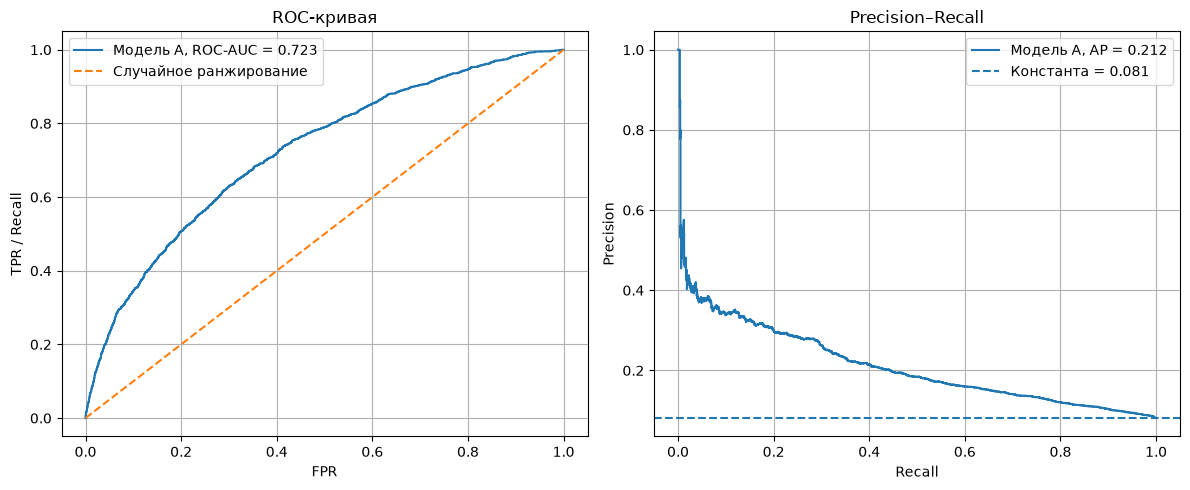

In [5]:
fpr, tpr, _ = roc_curve(y_test, p_test_a)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, p_test_a)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(
    fpr,
    tpr,
    label=f"Модель A, ROC-AUC = {roc_auc_score(y_test, p_test_a):.3f}",
)
axes[0].plot([0, 1], [0, 1], "--", label="Случайное ранжирование")
axes[0].set_title("ROC-кривая")
axes[0].set_xlabel("FPR")
axes[0].set_ylabel("TPR / Recall")
axes[0].legend()
axes[0].grid()

axes[1].plot(
    recall_curve,
    precision_curve,
    label=f"Модель A, AP = {average_precision_score(y_test, p_test_a):.3f}",
)
axes[1].axhline(
    y_test.mean(),
    linestyle="--",
    label=f"Константа = {y_test.mean():.3f}",
)
axes[1].set_title("Precision–Recall")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()